# 002 — Input normalisation and batch normalisation

Same protocol as `001` (see `001.md`), with two changes: (1) every acceleration channel is standardised (mean 0, std 1) with statistics fitted on the fit recordings only; (2) the network has batch normalisation after every convolution (`USE_BN`). Everything else is as in `001`. Estimates estimate `SB01_x` from the 75 bridge acceleration channels, training on the four `_02` sweeps and testing on the four `_01` sweeps (`DIRECTION = "forward"`). Set `DIRECTION = "reverse"` to swap the two sets.

Order of the steps (as in `001.md`): recordings are assigned to train / validation / test **first**, then the channel mean and standard deviation are computed on the fit recordings only (no PCA), then each recording is cut into windows. Windows never cross a recording boundary.

In [2]:
import os
os.environ["KERAS_BACKEND"] = "torch"   # must be set BEFORE importing keras

from pathlib import Path
import time

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import keras
from keras import layers
from numpy.lib.stride_tricks import sliding_window_view
from IPython.display import display

# --- data ---
PATH = Path("/mnt/c/Users/giuli/Documents/01_ACCADEMICO/2_PhD FIU/04 Didattica/CGN SHM/CGN project/data_100Hz.h5")
assert PATH is not None, "data_100Hz.h5 not found: put it in the data folder in the repository root"

# --- settings ---
DIRECTION = "forward"          # "forward": train on _02, test on _01 | "reverse": train on _01, test on _02
TARGET = "SB01_x"              # strain channel to predict [MPa]
FS = 100                       # sampling frequency [Hz]
WIN_S = 5                     # window length [s]
OVERLAP = 0.75                 # overlap between consecutive windows
WIN = int(WIN_S * FS)                                  # window length in samples (1000)
STRIDE = max(1, int(round(WIN * (1 - OVERLAP))))       # shift between window starts in samples (500)
CONFIGS = [{"name": "TCN, 75 channels"}]   # configurations compared on the validation folds (add more dicts to compare)
LR, BATCH, MAX_EPOCHS, PATIENCE = 1e-3, 32, 200, 20    # training settings
TCN_CHANNELS, TCN_KERNEL, TCN_DILATIONS = 16, 5, (1, 2, 4, 8, 16, 32, 64, 128)
POOL_AFTER, POOL_SIZE = (1, 3), 2     # blocks followed by a max pooling, and time steps merged by each pooling
USE_BN = True                  # batch normalisation after every convolution
BN_MOMENTUM = 0.9              # moving-average momentum of the BN statistics (low value: only a few batches per epoch)
SEED = 0
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

def receptive_field(dilations, pool_after, kernel, pool_size):
    rf, jump = 1, 1
    for i, d in enumerate(dilations):
        rf += (kernel - 1) * d * jump
        if i in pool_after:
            rf += (pool_size - 1) * jump
            jump *= pool_size
    return rf

rf = receptive_field(TCN_DILATIONS, POOL_AFTER, TCN_KERNEL, POOL_SIZE)
assert rf >= WIN, f"receptive field {rf} shorter than the window {WIN}"
print("Keras", keras.__version__, "| PyTorch", torch.__version__, "| device:", DEVICE)
print(f"Window {WIN} samples, stride {STRIDE} samples, receptive field {rf}")

Keras 3.15.1 | PyTorch 2.15.0+cu132 | device: cuda
Window 500 samples, stride 125 samples, receptive field 3952


## 1 Recordings and split

Only the undamaged sweeps (`UDS`, `SM`) are used. The repeat number defines the split: `_02` / `_01`.

In [3]:
with h5py.File(PATH, "r") as f:
    all_names = list(f.keys())

rows = []
for n in all_names:
    _, position, state, mode, direction, rep = n.split("_")      # MVS_P1_UDS_SM_Y_02
    rows.append({"name": n, "position": position, "state": state, "mode": mode, "direction": direction, "rep": rep})
meta = pd.DataFrame(rows)
meta = meta[(meta["state"] == "UDS") & (meta["mode"] == "SM")].reset_index(drop=True)
meta["setting"] = meta["position"] + "/" + meta["direction"]      # P1/Y, P1/Z, P2/Y, P2/Z
assert len(meta) == 8, len(meta)

train_rep, test_rep = ("02", "01") if DIRECTION == "forward" else ("01", "02")
train_names = list(meta[meta["rep"] == train_rep].sort_values("setting")["name"])
test_names = list(meta[meta["rep"] == test_rep].sort_values("setting")["name"])
setting_of = dict(zip(meta["name"], meta["setting"]))
assert len(train_names) == 4 and len(test_names) == 4
assert [setting_of[a] for a in train_names] == [setting_of[b] for b in test_names]   # same settings in the same order
rec_names = train_names + test_names
display(meta)

,name,position,state,mode,direction,rep,setting
0,MVS_P1_UDS_SM_Y_01,P1,UDS,SM,Y,01,P1/Y
1,MVS_P1_UDS_SM_Y_02,P1,UDS,SM,Y,02,P1/Y
2,MVS_P1_UDS_SM_Z_01,P1,UDS,SM,Z,01,P1/Z
3,MVS_P1_UDS_SM_Z_02,P1,UDS,SM,Z,02,P1/Z
4,MVS_P2_UDS_SM_Y_01,P2,UDS,SM,Y,01,P2/Y
5,MVS_P2_UDS_SM_Y_02,P2,UDS,SM,Y,02,P2/Y
6,MVS_P2_UDS_SM_Z_01,P2,UDS,SM,Z,01,P2/Z
7,MVS_P2_UDS_SM_Z_02,P2,UDS,SM,Z,02,P2/Z


## 2 Loading

Only the 75 acceleration channels and the target are read, as `float32`.

In [4]:
def is_wanted(ch):
    return ch.startswith("AL") or (ch.startswith("AG") and ch.endswith(("_y", "_z"))) or ch == TARGET   # 75 accelerations + target

def load_recording(name):
    cols = {}
    with h5py.File(PATH, "r") as f:
        for group in ("acceleration", "strain"):
            for sensor in f[name][group]:
                for axis in f[name][group][sensor]:
                    ch = f"{sensor}_{axis}"
                    if is_wanted(ch):
                        cols[ch] = f[name][group][sensor][axis][:].astype("float32")
        unit = f[name]["strain"][TARGET.split("_")[0]].attrs["unit"]
    d = pd.DataFrame(cols)
    d.index = np.arange(len(d)) / FS
    d.index.name = "Time [s]"
    return d, unit

rec, units = {}, set()
for n in rec_names:
    rec[n], u = load_recording(n)
    units.add(u)

acc_cols = sorted(c for c in rec[rec_names[0]].columns if c != TARGET)
assert len(acc_cols) == 75, len(acc_cols)
for n in rec_names:
    assert set(rec[n].columns) == set(acc_cols) | {TARGET}, n
    rec[n] = rec[n][acc_cols + [TARGET]]
assert len(units) == 1
target_unit = units.pop()

for n in rec_names:
    print(f"{n}: {len(rec[n])} samples ({len(rec[n]) / FS:.2f} s)")
n_train = sum(len(rec[n]) for n in train_names)
n_test = sum(len(rec[n]) for n in test_names)
print("Train samples:", n_train, "| test samples:", n_test, "| target unit:", target_unit)
expected = (249114, 249278) if DIRECTION == "forward" else (249278, 249114)    # from 001.md
assert (n_train, n_test) == expected, f"sample counts differ from 001.md: {(n_train, n_test)} vs {expected}"

MVS_P1_UDS_SM_Y_02: 61681 samples (616.81 s)
MVS_P1_UDS_SM_Z_02: 62531 samples (625.31 s)
MVS_P2_UDS_SM_Y_02: 62520 samples (625.20 s)
MVS_P2_UDS_SM_Z_02: 62382 samples (623.82 s)
MVS_P1_UDS_SM_Y_01: 62147 samples (621.47 s)
MVS_P1_UDS_SM_Z_01: 62410 samples (624.10 s)
MVS_P2_UDS_SM_Y_01: 62386 samples (623.86 s)
MVS_P2_UDS_SM_Z_01: 62335 samples (623.35 s)
Train samples: 249114 | test samples: 249278 | target unit: MPa


## 3 Preprocessing, windows, model

- `fit_scaler(names)`: mean and standard deviation of each of the 75 acceleration channels, computed on the given recordings only (never on validation or test). Every recording is then standardised with these numbers: `(x - mean) / std`. No PCA. The target is not scaled.
- `make_windows(n, scaler)`: one recording → windows of `WIN` samples every `STRIDE` samples. The target of a window is the strain at its last sample. The window positions depend only on the recording length, so every model sees the same target timestamps.
- `build_tcn`: causal temporal convolutional network, kept from the PCA + TCN notebook (with max pooling after blocks 1 and 3), plus a `BatchNormalization` layer after the input projection and after every dilated convolution (before the skip sum).

In [5]:
def fit_scaler(names):
    """Mean and std of each acceleration channel, from the given recordings only."""
    X = np.concatenate([rec[n][acc_cols].values for n in names])
    mean = X.mean(axis=0, dtype="float64")
    std = X.std(axis=0, dtype="float64")
    return mean.astype("float32"), (std + 1e-8).astype("float32")     # 1e-8: avoids dividing by zero on a dead channel

def make_windows(n, scaler):
    mean, std = scaler
    d = rec[n]
    Z = ((d[acc_cols].values - mean) / std).astype("float32")
    y = d[TARGET].values.astype("float32")
    assert len(d) >= WIN
    X = sliding_window_view(Z, WIN, axis=0)                           # (windows, 75, WIN)
    X = np.ascontiguousarray(X.transpose(0, 2, 1)[::STRIDE])          # (windows, WIN, 75), one every STRIDE
    y_w = y[WIN - 1:][::STRIDE]                                       # target = value at the last sample
    t_end = d.index.values[WIN - 1:][::STRIDE]
    return X, y_w, t_end

def stack_windows(names, scaler):
    parts = [make_windows(n, scaler) for n in names]
    return tuple(np.concatenate([p[k] for p in parts]) for k in range(3))

def build_tcn(n_features):
    inputs = layers.Input(shape=(None, n_features))
    x = layers.Conv1D(TCN_CHANNELS, 1, padding="causal")(inputs)
    if USE_BN:
        x = layers.BatchNormalization(momentum=BN_MOMENTUM)(x)
    for i, dil in enumerate(TCN_DILATIONS):
        res = x
        x = layers.Conv1D(TCN_CHANNELS, TCN_KERNEL, padding="causal", dilation_rate=dil)(x)
        if USE_BN:
            x = layers.BatchNormalization(momentum=BN_MOMENTUM)(x)     # before the skip sum
        x = layers.Activation("relu")(layers.Add()([res, x]))
        if i in POOL_AFTER:                                           # pooling after the sum and the ReLU
            x = layers.MaxPooling1D(pool_size=POOL_SIZE, padding="same")(x)
    out = layers.Dense(1)(x[:, -1, :])
    model = keras.Model(inputs, out)
    model.compile(optimizer=keras.optimizers.Adam(LR), loss="mse")
    return model

def train_tcn(X, y, X_val=None, y_val=None, epochs=MAX_EPOCHS):
    """With validation data: early stopping, restores the best weights. Without: exactly `epochs` epochs."""
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    with keras.device(DEVICE):
        model = build_tcn(X.shape[2])
        if X_val is not None:
            es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
            h = model.fit(X, y, validation_data=(X_val, y_val), epochs=epochs, batch_size=BATCH, verbose=0, callbacks=[es])
            best = int(np.argmin(h.history["val_loss"])) + 1
        else:
            h = model.fit(X, y, epochs=epochs, batch_size=BATCH, verbose=0)
            best = epochs
    return model, best, h.history

def predict(model, X):
    with keras.device(DEVICE):
        return model.predict(X, batch_size=256, verbose=0).ravel()

def rmse(t, p): return float(np.sqrt(np.mean((t - p) ** 2)))
def r2(t, p): return float(1 - np.sum((t - p) ** 2) / np.sum((t - t.mean()) ** 2))

## 4 Validation folds (training recordings only)

Four folds. Each fold holds out one whole training recording (one shaker setting) for validation; the channel mean/std and the network are fitted on the other three. The test recordings are not touched here.

In [12]:
cv_rows = []
cv_hist = {}
for ci, cfg in enumerate(CONFIGS):
    for k, val_name in enumerate(train_names):
        fit_names = [n for n in train_names if n != val_name]
        scaler_k = fit_scaler(fit_names)
        X_fit, y_fit, _ = stack_windows(fit_names, scaler_k)
        X_val, y_val, _ = make_windows(val_name, scaler_k)
        t0 = time.perf_counter()
        model, best, h = train_tcn(X_fit, y_fit, X_val, y_val)
        cv_hist[(ci, k)] = h
        p = predict(model, X_val)
        cv_rows.append({"config": ci, "name": cfg["name"], "fold": k + 1, "validation": val_name,
                        "fit windows": len(X_fit), "val windows": len(X_val), "best epoch": best,
                        "val RMSE": rmse(y_val, p), "val R2": r2(y_val, p),
                        "baseline RMSE": rmse(y_val, np.full_like(y_val, y_fit.mean())),
                        "seconds": time.perf_counter() - t0})
        print(cv_rows[-1])

cv = pd.DataFrame(cv_rows)
display(cv.round(4))
summary = cv.groupby("config")[["val RMSE", "val R2", "best epoch"]].mean()
display(summary.round(4))
best_config = int(summary["val RMSE"].idxmin())
final_epochs = int(round(cv[cv["config"] == best_config]["best epoch"].median()))
print(f"Selected config {best_config}: {CONFIGS[best_config]} | epochs for the final fit: {final_epochs}")

{'config': 0, 'name': 'TCN, 75 channels', 'fold': 1, 'validation': 'MVS_P1_UDS_SM_Y_02', 'fit windows': 1490, 'val windows': 490, 'best epoch': 95, 'val RMSE': 0.08299408853054047, 'val R2': -1.0236084461212158, 'baseline RMSE': 0.058494940400123596, 'seconds': 228.06072051799993}
{'config': 0, 'name': 'TCN, 75 channels', 'fold': 2, 'validation': 'MVS_P1_UDS_SM_Z_02', 'fit windows': 1483, 'val windows': 497, 'best epoch': 117, 'val RMSE': 0.07539395242929459, 'val R2': -0.3509559631347656, 'baseline RMSE': 0.06487175822257996, 'seconds': 321.515127615}
{'config': 0, 'name': 'TCN, 75 channels', 'fold': 3, 'validation': 'MVS_P2_UDS_SM_Y_02', 'fit windows': 1483, 'val windows': 497, 'best epoch': 190, 'val RMSE': 0.07129237800836563, 'val R2': -0.29324162006378174, 'baseline RMSE': 0.06272821873426437, 'seconds': 503.7056812109997}
{'config': 0, 'name': 'TCN, 75 channels', 'fold': 4, 'validation': 'MVS_P2_UDS_SM_Z_02', 'fit windows': 1484, 'val windows': 496, 'best epoch': 70, 'val RMSE':

,config,name,fold,validation,fit windows,val windows,best epoch,val RMSE,val R2,baseline RMSE,seconds
0,0,"TCN, 75 channels",1,MVS_P1_UDS_SM_Y_02,1490,490,95,0.0830,-1.0236,0.0585,228.0607
1,0,"TCN, 75 channels",2,MVS_P1_UDS_SM_Z_02,1483,497,117,0.0754,-0.3510,0.0649,321.5151
2,0,"TCN, 75 channels",3,MVS_P2_UDS_SM_Y_02,1483,497,190,0.0713,-0.2932,0.0627,503.7057
3,0,"TCN, 75 channels",4,MVS_P2_UDS_SM_Z_02,1484,496,70,0.0832,-0.1572,0.0775,231.5658


,val RMSE,val R2,best epoch
config,,,
0,0.0782,-0.4563,118.0


Selected config 0: {'name': 'TCN, 75 channels'} | epochs for the final fit: 106


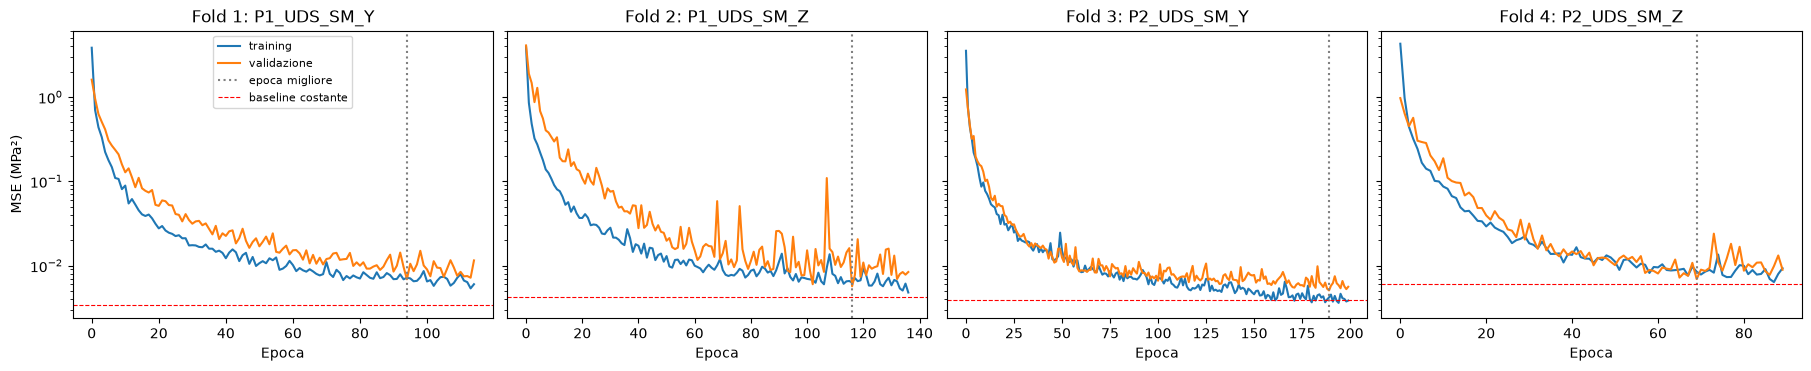

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6), constrained_layout=True, sharey=True)
for k, ax in enumerate(axes):
    h = cv_hist[(best_config, k)]
    row = cv[(cv["config"] == best_config) & (cv["fold"] == k + 1)].iloc[0]
    ax.plot(h["loss"], label="training")
    ax.plot(h["val_loss"], label="validazione")
    ax.axvline(row["best epoch"] - 1, color="gray", ls=":", label="epoca migliore")
    ax.axhline(row["baseline RMSE"] ** 2, color="red", ls="--", lw=0.8, label="baseline costante")
    ax.set(title=f"Fold {k + 1}: {row['validation'][4:-3]}", xlabel="Epoca", yscale="log")
axes[0].set_ylabel("MSE (MPa²)")
axes[0].legend(fontsize=8)
plt.show()

## 5 Final fit on all four training recordings and test

The selected configuration is refitted on the four training recordings (channel mean and std included), with the number of epochs found in the validation folds. No validation set remains for early stopping. Then it is scored on each test recording.
Baseline: constant prediction equal to the mean of the training window targets.

In [17]:
cfg = CONFIGS[best_config]
scaler_f = fit_scaler(train_names)
X_tr, y_tr, _ = stack_windows(train_names, scaler_f)
model_f, _, hist = train_tcn(X_tr, y_tr, epochs=final_epochs)
print(f"Train windows: {len(X_tr)} | final training loss: {hist['loss'][-1]:.5f}")

rows, test_pred = [], {}
for n_te, n_tr in zip(test_names, train_names):
    X_te, y_te, t_te = make_windows(n_te, scaler_f)
    p = predict(model_f, X_te)
    base = np.full_like(y_te, y_tr.mean())
    test_pred[n_te] = (t_te, y_te, p)
    rows.append({"setting": setting_of[n_te], "test recording": n_te, "windows": len(y_te),
                 "RMSE model": rmse(y_te, p), "R2 model": r2(y_te, p),
                 "RMSE baseline": rmse(y_te, base), "R2 baseline": r2(y_te, base)})
res = pd.DataFrame(rows)
mean_row = {"setting": "mean", "test recording": "", "windows": int(res["windows"].sum())}
for c in ("RMSE model", "R2 model", "RMSE baseline", "R2 baseline"):
    mean_row[c] = res[c].mean()                         # equally weighted mean of the four recordings
res = pd.concat([res, pd.DataFrame([mean_row])], ignore_index=True)
print(f"Direction: {DIRECTION} | RMSE in {target_unit}")
display(res.round(4))

Train windows: 1980 | final training loss: 0.00589
Direction: forward | RMSE in MPa


,setting,test recording,windows,RMSE model,R2 model,RMSE baseline,R2 baseline
0,P1/Y,MVS_P1_UDS_SM_Y_01,494,0.1568,-0.0631,0.1521,-0.0001
1,P1/Z,MVS_P1_UDS_SM_Z_01,496,0.1555,-0.0876,0.1491,-0.0000
2,P2/Y,MVS_P2_UDS_SM_Y_01,496,0.2039,-0.0928,0.1951,-0.0001
3,P2/Z,MVS_P2_UDS_SM_Z_01,495,0.1811,0.0189,0.1828,-0.0000
4,mean,,1981,0.1743,-0.0561,0.1698,-0.0001


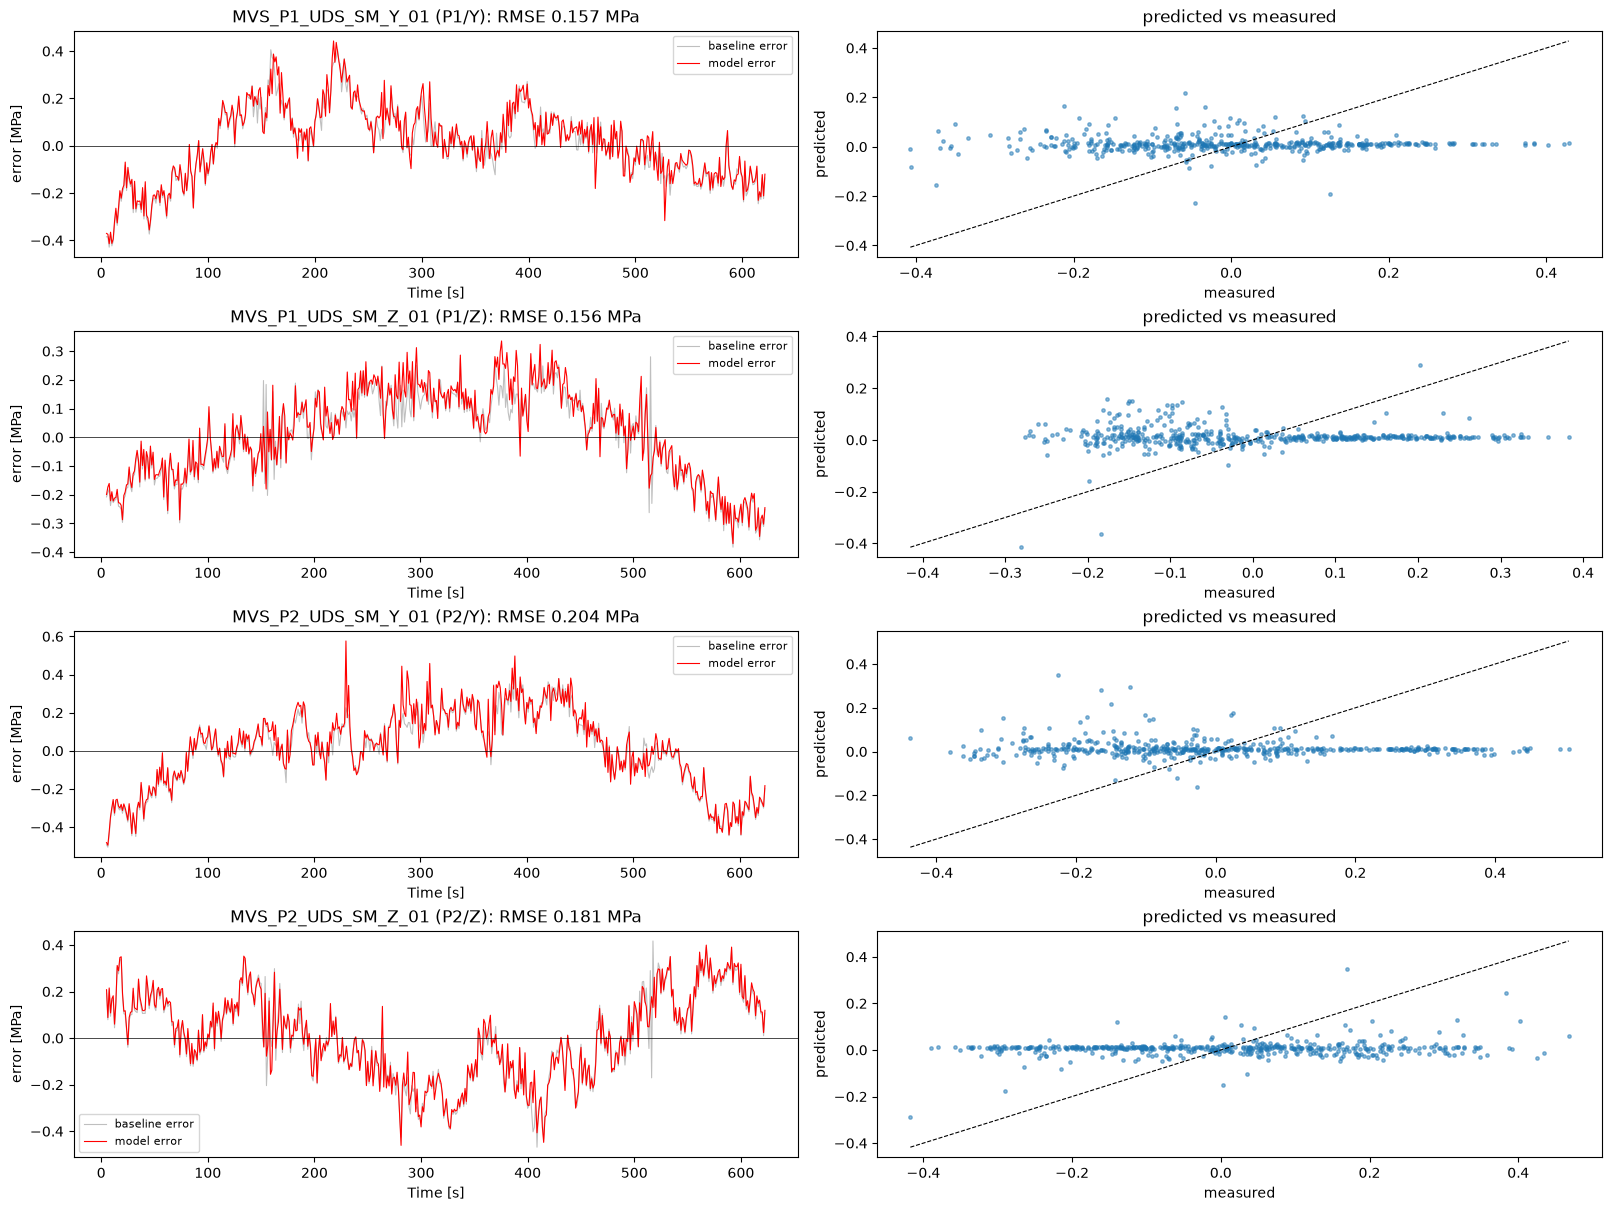

In [18]:
fig, axes = plt.subplots(4, 2, figsize=(16, 12), constrained_layout=True)
for i, n in enumerate(test_names):
    t, y, p = test_pred[n]
    e = p - y                                    # model error
    e_base = y_tr.mean() - y                     # error of the constant baseline
    axes[i, 0].plot(t, e_base, color="gray", alpha=0.5, lw=0.8, label="baseline error")
    axes[i, 0].plot(t, e, color="red", lw=0.8, label="model error")
    axes[i, 0].axhline(0, color="black", lw=0.5)
    axes[i, 0].set(title=f"{n} ({setting_of[n]}): RMSE {np.sqrt(np.mean(e ** 2)):.3f} {target_unit}",
                   xlabel="Time [s]", ylabel=f"error [{target_unit}]")
    axes[i, 0].legend(fontsize=8)
    axes[i, 1].scatter(y, p, s=6, alpha=0.5)
    lim = [min(y.min(), p.min()), max(y.max(), p.max())]
    axes[i, 1].plot(lim, lim, "k--", lw=0.8)
    axes[i, 1].set(title="predicted vs measured", xlabel="measured", ylabel="predicted")
plt.show()

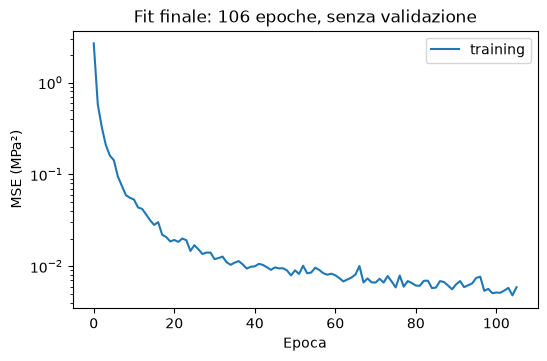

In [19]:
plt.figure(figsize=(6, 3.6))
plt.plot(hist["loss"], label="training")
plt.xlabel("Epoca"); plt.ylabel("MSE (MPa²)"); plt.yscale("log")
plt.title(f"Fit finale: {final_epochs} epoche, senza validazione")
plt.legend(); plt.show()


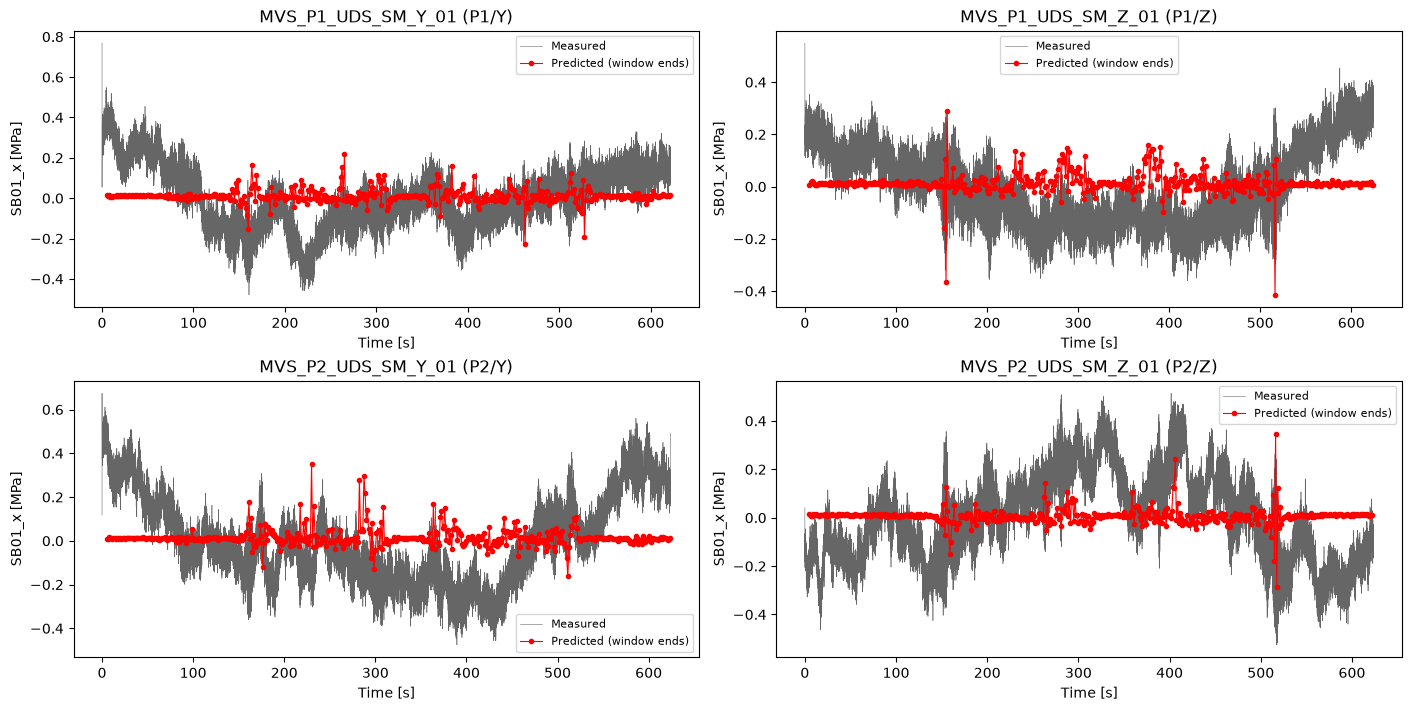

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7), constrained_layout=True)
for ax, n in zip(axes.ravel(), test_names):
    t, y, p = test_pred[n]
    ax.plot(rec[n].index, rec[n][TARGET], color="black", lw=0.4, alpha=0.6, label="Measured")
    ax.plot(t, p, "o-", color="red", ms=3, lw=0.8, label="Predicted (window ends)")
    ax.set(title=f"{n} ({setting_of[n]})", xlabel="Time [s]", ylabel=f"{TARGET} [{target_unit}]")
    ax.legend(fontsize=8)
plt.show()

## 6 Diagnostics: is there information in the data?

The network does not beat the constant baseline. Before adding complexity, these cells separate the possible causes.

1. **Metrics on training and test.** R², correlation, and R² after the best multiplicative gain on the predictions (it removes a wrong amplitude and keeps the shape). Uses `model_f`, `scaler_f` from the final fit.
2. **Predictions over time.** A 20 s segment of one training and one test recording, a prediction at every sample.
3. **Ridge diagnostic** (linear model, no network). Two tasks: the **envelope** (log of the strain RMS in each window, built from log band powers of the 75 channels) and the **instantaneous strain** (from lagged acceleration samples). The 4 validation folds as before; the test only at the end.

In [21]:
def corr(t, p):
    return float(np.corrcoef(t, p)[0, 1])

def r2_best_gain(t, p):
    g = float(np.dot(p, t) / np.dot(p, p))          # best multiplicative factor for the predictions
    return r2(t, g * p), g

rows = []
for split, names in (("train", train_names), ("test", test_names)):
    for n in names:
        X_, y_, _ = make_windows(n, scaler_f)
        p = predict(model_f, X_)
        r2g, g = r2_best_gain(y_, p)
        rows.append({"set": split, "recording": n, "RMSE": rmse(y_, p), "target std": float(y_.std()),
                     "R2": r2(y_, p), "corr": corr(y_, p), "R2 (best gain)": r2g, "gain": g})
diag = pd.DataFrame(rows)
display(diag.round(3))
display(diag.groupby("set")[["RMSE", "target std", "R2", "corr", "R2 (best gain)"]].mean().round(3))

,set,recording,RMSE,target std,R2,corr,R2 (best gain),gain
0,train,MVS_P1_UDS_SM_Y_02,0.059,0.058,-0.039,0.287,0.077,0.453
1,train,MVS_P1_UDS_SM_Z_02,0.062,0.065,0.081,0.427,0.150,0.595
2,train,MVS_P2_UDS_SM_Y_02,0.060,0.063,0.077,0.326,0.096,0.689
3,train,MVS_P2_UDS_SM_Z_02,0.072,0.077,0.135,0.395,0.135,1.009
4,test,MVS_P1_UDS_SM_Y_01,0.157,0.152,-0.063,-0.002,-0.000,-0.025
5,test,MVS_P1_UDS_SM_Z_01,0.156,0.149,-0.088,0.013,0.000,0.040
6,test,MVS_P2_UDS_SM_Y_01,0.204,0.195,-0.093,-0.091,0.008,-0.395
7,test,MVS_P2_UDS_SM_Z_01,0.181,0.183,0.019,0.149,0.021,0.747


,RMSE,target std,R2,corr,R2 (best gain)
set,,,,,
test,0.174,0.170,-0.056,0.017,0.007
train,0.063,0.066,0.063,0.359,0.115


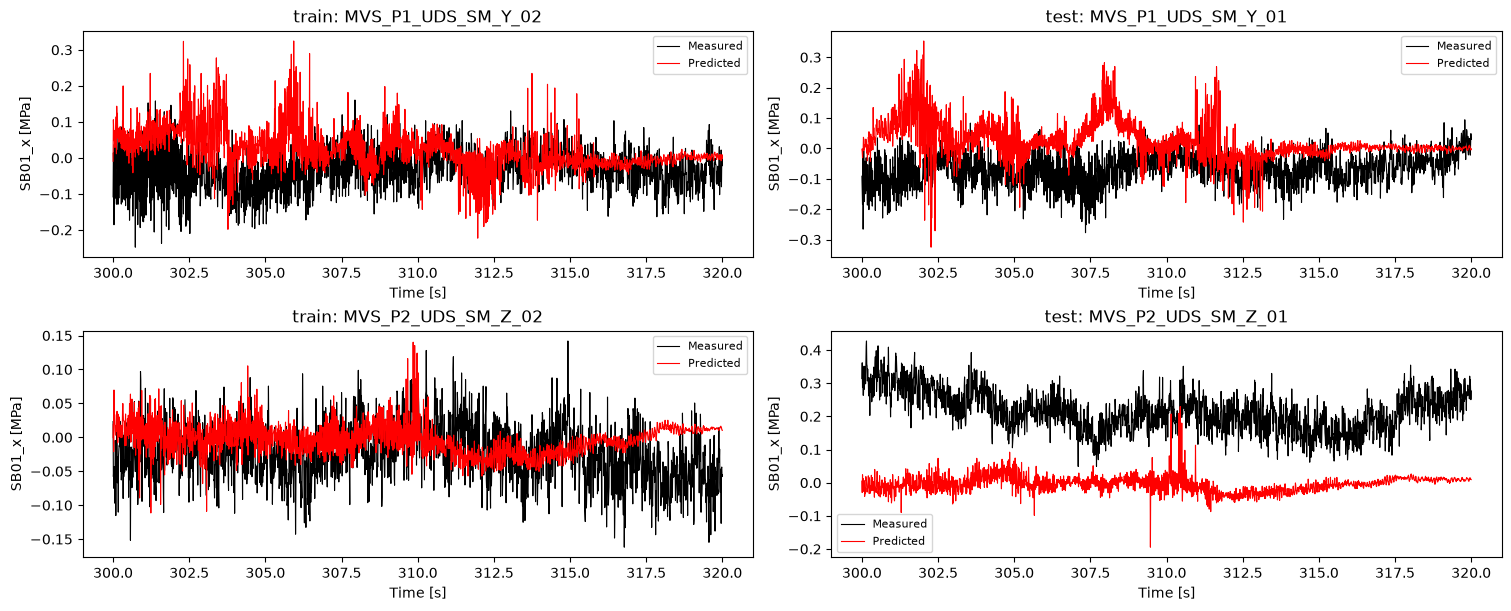

In [22]:
def predict_dense(n, scaler, t0, t1):
    """Prediction for every window ending at every sample between t0 and t1 seconds."""
    mean, std = scaler
    d = rec[n]
    Z = ((d[acc_cols].values - mean) / std).astype("float32")
    sw = sliding_window_view(Z, WIN, axis=0)
    t = d.index.values
    ends = np.arange(WIN - 1, len(Z))
    ends = ends[(t[ends] >= t0) & (t[ends] <= t1)]
    X_ = np.ascontiguousarray(sw[ends - (WIN - 1)].transpose(0, 2, 1))
    return t[ends], predict(model_f, X_)

T0, T1 = 300, 320                                    # seconds shown
shown = [(train_names[0], "train"), (test_names[0], "test"), (train_names[3], "train"), (test_names[3], "test")]
fig, axes = plt.subplots(2, 2, figsize=(15, 6), constrained_layout=True)
for ax, (n, split) in zip(axes.ravel(), shown):
    t_p, y_p = predict_dense(n, scaler_f, T0, T1)
    seg = rec[n].loc[T0:T1, TARGET]
    ax.plot(seg.index, seg.values, color="black", lw=0.8, label="Measured")
    ax.plot(t_p, y_p, color="red", lw=0.8, label="Predicted")
    ax.set(title=f"{split}: {n}", xlabel="Time [s]", ylabel=f"{TARGET} [{target_unit}]")
    ax.legend(fontsize=8)
plt.show()

In [23]:
from sklearn.linear_model import Ridge

scaler_f = fit_scaler(train_names)        # channel mean/std of the 4 training recordings (no network needed)
def corr(t, p):
    return float(np.corrcoef(t, p)[0, 1])

BANDS = [(0.5, 2), (2, 5), (5, 10), (10, 20), (20, 40)]      # Hz
LAGS = np.arange(0, 100, 5)                                  # samples back from the end of the window (0 to 1 s)
freqs = np.fft.rfftfreq(WIN, 1 / FS)
band_idx = [(freqs >= lo) & (freqs < hi) for lo, hi in BANDS]

def window_data(n, scaler):
    X, y, _ = make_windows(n, scaler)                                           # (windows, WIN, 75), standardised
    F = np.abs(np.fft.rfft(X * np.hanning(WIN)[None, :, None], axis=1)) ** 2
    band = np.stack([F[:, m, :].sum(axis=1) for m in band_idx], axis=1)         # (windows, bands, 75)
    f_env = np.log10(band + 1e-12).reshape(len(X), -1)                          # envelope features
    f_lag = X[:, WIN - 1 - LAGS, :].reshape(len(X), -1)                         # lagged samples
    yw = sliding_window_view(rec[n][TARGET].values.astype("float64"), WIN)[::STRIDE]
    env = np.log10(np.sqrt((yw ** 2).mean(axis=1)))                             # envelope target: log10 of the strain RMS
    assert len(env) == len(y)
    return f_env, f_lag, env, y

def get(names, scaler):
    parts = [window_data(n, scaler) for n in names]
    return [np.concatenate([p[k] for p in parts]) for k in range(4)]

def fit_eval(Xa, ya, Xb, alpha):
    mu, sd = Xa.mean(0), Xa.std(0) + 1e-8                                       # feature standardisation: fit windows only
    return Ridge(alpha=alpha).fit((Xa - mu) / sd, ya).predict((Xb - mu) / sd)

tasks = {"envelope (log10 RMS)": (0, 2), "instantaneous strain": (1, 3)}        # (feature index, target index)
alphas = [1, 10, 100, 1e3, 1e4]

rd_rows = []
for k, val_name in enumerate(train_names):
    fit_names = [n for n in train_names if n != val_name]
    sc = fit_scaler(fit_names)
    A, B = get(fit_names, sc), get([val_name], sc)
    for task, (fi, ti) in tasks.items():
        for a in alphas:
            p = fit_eval(A[fi], A[ti], B[fi], a)
            rd_rows.append({"task": task, "alpha": a, "fold": k + 1, "R2": r2(B[ti], p), "corr": corr(B[ti], p)})
rd = pd.DataFrame(rd_rows)
summ = rd.groupby(["task", "alpha"])[["R2", "corr"]].mean()
print("Validation folds, mean over the 4 folds:")
display(summ.round(3))

A = get(train_names, scaler_f)
test_rows = []
for task, (fi, ti) in tasks.items():
    a_best = summ.loc[task]["R2"].idxmax()                                      # alpha chosen on the validation folds only
    for n in test_names:
        B = get([n], scaler_f)
        p = fit_eval(A[fi], A[ti], B[fi], a_best)
        test_rows.append({"task": task, "alpha": a_best, "test recording": n, "R2": r2(B[ti], p), "corr": corr(B[ti], p)})
rt = pd.DataFrame(test_rows)
print("Test recordings:")
display(rt.round(3))
display(rt.groupby("task")[["R2", "corr"]].mean().round(3))

Validation folds, mean over the 4 folds:


R2   corr
task                 alpha                 
envelope (log10 RMS) 1.0      -0.698  0.337
                     10.0     -0.344  0.383
                     100.0    -0.161  0.410
                     1000.0   -0.108  0.405
                     10000.0  -0.058  0.423
instantaneous strain 1.0     -25.495  0.027
                     10.0     -4.371  0.119
                     100.0    -0.728  0.224
                     1000.0    0.040  0.318
                     10000.0   0.119  0.345

Test recordings:


,task,alpha,test recording,R2,corr
0,envelope (log10 RMS),10000.0,MVS_P1_UDS_SM_Y_01,-1.968,-0.143
1,envelope (log10 RMS),10000.0,MVS_P1_UDS_SM_Z_01,-4.468,-0.519
2,envelope (log10 RMS),10000.0,MVS_P2_UDS_SM_Y_01,-2.456,-0.275
3,envelope (log10 RMS),10000.0,MVS_P2_UDS_SM_Z_01,-2.717,-0.050
4,instantaneous strain,10000.0,MVS_P1_UDS_SM_Y_01,0.028,0.181
5,instantaneous strain,10000.0,MVS_P1_UDS_SM_Z_01,0.031,0.177
6,instantaneous strain,10000.0,MVS_P2_UDS_SM_Y_01,-0.010,0.011
7,instantaneous strain,10000.0,MVS_P2_UDS_SM_Z_01,0.036,0.189


,R2,corr
task,,
envelope (log10 RMS),-2.902,-0.247
instantaneous strain,0.021,0.139


## 7 Normalised strain target (quick check, no folds)

Same network and same inputs as above, but the **target is standardised**: `z = (strain - mean) / std`, with mean and std of the training windows only. The network predicts `z`; the predictions are converted back to MPa (`z * std + mean`) before RMSE and R² are computed, so the numbers are comparable with section 5.

This section is self-contained: it needs only the setup cells (settings, split, loading, functions). It does **not** rerun the validation folds and has no validation set, so the number of epochs is fixed (`EPOCHS_NORM`: the `final_epochs` of section 4 if it exists, otherwise 103, the median found earlier).

In [6]:
EPOCHS_NORM = globals().get("final_epochs", 103)      # fixed number of epochs (103 = median of the earlier folds)

scaler_n = fit_scaler(train_names)                    # channel mean/std from the 4 training recordings
X_trn, y_trn, _ = stack_windows(train_names, scaler_n)
y_mean, y_std = float(y_trn.mean()), float(y_trn.std())            # target statistics: training windows only
y_trn_z = ((y_trn - y_mean) / y_std).astype("float32")

model_z, _, hist_z = train_tcn(X_trn, y_trn_z, epochs=EPOCHS_NORM)
print(f"target mean {y_mean:+.4f} | std {y_std:.4f} {target_unit} | epochs {EPOCHS_NORM} | final training loss (normalised units): {hist_z['loss'][-1]:.4f}")

target mean -0.0006 | std 0.0663 MPa | epochs 103 | final training loss (normalised units): 0.1918


In [7]:
def to_mpa(z):
    return z * y_std + y_mean                          # back to the physical unit

p_trn = to_mpa(predict(model_z, X_trn))
print(f"train: RMSE {rmse(y_trn, p_trn):.4f} {target_unit} | R2 {r2(y_trn, p_trn):.3f} | corr {np.corrcoef(y_trn, p_trn)[0, 1]:.3f}")

rows, test_pred_z = [], {}
for n_te in test_names:
    X_te, y_te, t_te = make_windows(n_te, scaler_n)
    p = to_mpa(predict(model_z, X_te))
    test_pred_z[n_te] = (t_te, y_te, p)
    rows.append({"setting": setting_of[n_te], "test recording": n_te, "windows": len(y_te),
                 "RMSE model": rmse(y_te, p), "R2 model": r2(y_te, p),
                 "corr": float(np.corrcoef(y_te, p)[0, 1]),
                 "RMSE baseline": rmse(y_te, np.full_like(y_te, y_mean))})
res_z = pd.DataFrame(rows)
mean_row = {"setting": "mean", "test recording": "", "windows": int(res_z["windows"].sum())}
for c in ("RMSE model", "R2 model", "corr", "RMSE baseline"):
    mean_row[c] = res_z[c].mean()
res_z = pd.concat([res_z, pd.DataFrame([mean_row])], ignore_index=True)
print(f"Normalised target | direction: {DIRECTION} | RMSE in {target_unit}")
display(res_z.round(4))
if "res" in globals():
    print("Section 5 (target not scaled), for comparison:")
    display(res[["setting", "RMSE model", "R2 model", "RMSE baseline"]].round(4))

train: RMSE 0.0245 MPa | R2 0.863 | corr 0.932
Normalised target | direction: forward | RMSE in MPa


,setting,test recording,windows,RMSE model,R2 model,corr,RMSE baseline
0,P1/Y,MVS_P1_UDS_SM_Y_01,494,0.1539,-0.0239,0.1083,0.1521
1,P1/Z,MVS_P1_UDS_SM_Z_01,496,0.1463,0.0382,0.2561,0.1491
2,P2/Y,MVS_P2_UDS_SM_Y_01,496,0.2011,-0.0632,-0.0098,0.1951
3,P2/Z,MVS_P2_UDS_SM_Z_01,495,0.2042,-0.2474,-0.1783,0.1828
4,mean,,1981,0.1764,-0.0741,0.0441,0.1698
